# Uczenie głębokie — Zajęcia 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_6.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_6/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Trening w praktyce — optymalizatory, regularyzacja i funkcje straty

Na poprzednich zajęciach zostawiliśmy dwa problemy. Pierwszy: duża sieć
5 → 64 → 64 → 1 nauczyła się danych na pamięć i na teście wypadła gorzej niż
jeden neuron. Drugi, mniej widoczny: zwykły spadek gradientu (SGD) jest
powolny i bardzo czuły na współczynnik uczenia. Dziś naprawiamy oba. Poznasz
trzy pokrętła, które ustawia każdy, kto trenuje sieci: **optymalizator**,
**regularyzację** i **funkcję straty**.

Przy funkcji straty wyjdziemy wreszcie poza klasyfikację. Sieć nie musi
odpowiadać „tak/nie" — może przewidywać **liczbę**. Na danych MeritoEats
z dzisiejszych zajęć z DS w Pythonie zbudujemy sieć, która przewiduje, ile
minut potrwa dostawa.

Po dzisiejszych zajęciach będziesz w stanie:

- porównać SGD, SGD z momentum i Adam i wybrać rozsądny punkt startu,
- zatrzymać trening we właściwym momencie i odzyskać najlepsze wagi
  (wczesne zatrzymanie),
- zastosować weight decay i dropout i wyjaśnić, dlaczego działają,
- pamiętać o `model.train()` i `model.eval()`,
- dobrać ostatnią warstwę i funkcję straty do zadania — klasyfikacji albo
  regresji,
- zbudować sieć do regresji w PyTorch i ocenić ją średnim błędem w minutach.

> ℹ️ **Godzinę temu na Data Science w Pythonie**
>
> Robiliśmy mini-projekt dla MeritoEats. Wyszło, że oceny spadają nie przez
> długie dostawy, tylko przez **niedotrzymane obietnice**, a aplikacja
> obiecuje ten sam czas o 15:00 i o 19:00. Dziś sprawdzimy, czy sieć
> neuronowa przewidzi czas dostawy lepiej niż wzór, którego używa aplikacja.


## Plan na dziś

| Blok | Czas |
|---|---|
| Nowa wersja funkcji `trenuj` | 3 min |
| Optymalizatory — SGD, momentum, Adam | 8 min |
| Wczesne zatrzymanie | 7 min |
| Weight decay i dropout | 10 min |
| Funkcje straty — klasyfikacja i regresja | 5 min |
| Sieć do regresji — czas dostawy | 10 min |
| Ściągawka | 2 min |
| **Zadanie 6** | **45 min** |


## Przygotowanie

### Dane

Pierwsza część zajęć to znowu siłownia — te same trzy zbiory co na
zajęciach 5:

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, f1_score, mean_absolute_error

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/silownia_czyste.csv"
df = pd.read_csv(URL)

cechy = ["wiek", "oplata_mies", "staz_mies", "wizyty_mies", "zgloszenia"]
X_train, X_test, y_train, y_test = train_test_split(
    df[cechy], df["zrezygnowal"], test_size=0.2, random_state=42, stratify=df["zrezygnowal"])
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

scaler = StandardScaler().fit(X_tr)
X_tr_t = torch.tensor(scaler.transform(X_tr), dtype=torch.float32)
X_val_t = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
X_test_t = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_tr_t = torch.tensor(y_tr.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)

dane = (X_tr_t, y_tr_t, X_val_t, y_val_t)

`dane` to po prostu cztery tensory spakowane razem, żeby nie przepisywać ich
przy każdym wywołaniu.

### Nowa wersja funkcji `trenuj`

Funkcja z zajęć 5 sama tworzyła optymalizator i stratę. Dziś będziemy je
zmieniać, więc podajemy je z zewnątrz. Dochodzą też dwie rzeczy, które
wyjaśnimy za chwilę — oznaczone w komentarzach:

In [2]:
def trenuj(model, dane, funkcja_straty, optymalizator, epoki=100, cierpliwosc=None):
    X_tr_t, y_tr_t, X_val_t, y_val_t = dane
    paczki = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

    historia_tr, historia_val = [], []
    najlepsza_strata, najlepsze_wagi, bez_poprawy = float("inf"), None, 0
    for epoka in range(epoki):
        model.train()                                   # tryb treningu (dropout)
        suma = 0
        for xb, yb in paczki:
            optymalizator.zero_grad()
            strata = funkcja_straty(model(xb), yb)
            strata.backward()
            optymalizator.step()
            suma += strata.item()
        historia_tr.append(suma / len(paczki))

        model.eval()                                    # tryb oceny (dropout)
        with torch.no_grad():
            strata_val = funkcja_straty(model(X_val_t), y_val_t).item()
        historia_val.append(strata_val)

        if strata_val < najlepsza_strata:               # wczesne zatrzymanie
            najlepsza_strata, bez_poprawy = strata_val, 0
            najlepsze_wagi = copy.deepcopy(model.state_dict())
        else:
            bez_poprawy += 1
            if cierpliwosc is not None and bez_poprawy >= cierpliwosc:
                break

    if cierpliwosc is not None:
        model.load_state_dict(najlepsze_wagi)           # wracamy do najlepszej epoki
    return historia_tr, historia_val


def ocen(model, X_t, y):
    model.eval()
    with torch.no_grad():
        p = model(X_t).numpy().ravel()
    return round(log_loss(y, p), 3), round(f1_score(y, (p > 0.5).astype(int)), 3)

Środek — pięć kroków w pętli po paczkach — jest dokładnie taki jak na
zajęciach 5.


## Optymalizatory

### SGD, momentum i Adam

Optymalizator to „ten, który robi kroki" — decyduje, jak na podstawie
gradientu zmienić wagi. Do tej pory używaliśmy najprostszego, **SGD**: krok =
współczynnik uczenia × gradient. Wytrenujmy tę samą sieć 5 → 8 → 1 trzema
optymalizatorami, z tym samym `lr=0.01`:

SGD             strata po 5 epokach: 0.571   po 50: 0.494
SGD z momentum  strata po 5 epokach: 0.498   po 50: 0.430


Adam            strata po 5 epokach: 0.473   po 50: 0.418


Text(0, 0.5, 'strata treningowa (BCE)')

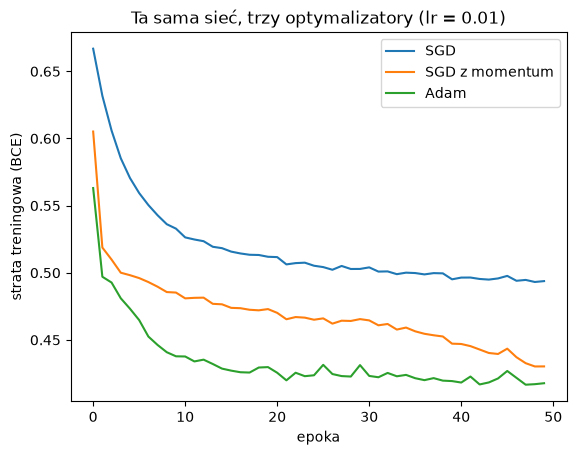

In [3]:
for nazwa in ["SGD", "SGD z momentum", "Adam"]:
    torch.manual_seed(42)
    siec = nn.Sequential(nn.Linear(5, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())

    if nazwa == "SGD":
        optymalizator = torch.optim.SGD(siec.parameters(), lr=0.01)
    elif nazwa == "SGD z momentum":
        optymalizator = torch.optim.SGD(siec.parameters(), lr=0.01, momentum=0.9)
    else:
        optymalizator = torch.optim.Adam(siec.parameters(), lr=0.01)

    historia_tr, historia_val = trenuj(siec, dane, nn.BCELoss(), optymalizator, epoki=50)
    plt.plot(historia_tr, label=nazwa)
    print(f"{nazwa:15} strata po 5 epokach: {historia_tr[4]:.3f}   po 50: {historia_tr[-1]:.3f}")

plt.legend()
plt.title("Ta sama sieć, trzy optymalizatory (lr = 0.01)")
plt.xlabel("epoka")
plt.ylabel("strata treningowa (BCE)")

- **SGD** z `lr=0.01` ledwo się rusza — po 50 epokach jest tam, gdzie Adam był
  po kilku. Na zajęciach 5 działał, bo daliśmy mu dziesięć razy większy krok.
- **Momentum** („pęd") dodaje do każdego kroku część poprzedniego. Wracamy do
  schodzenia z góry we mgle: zamiast stawiać każdy krok od zera, toczysz się
  jak kula — na długim, łagodnym zboczu nabierasz prędkości, a drobne nierówności
  nie zbijają Cię z kursu. `momentum=0.9` to wartość, którą prawie wszyscy
  zostawiają.
- **Adam** idzie dalej: oprócz pędu pilnuje **osobnej długości kroku dla każdej
  wagi**. Waga, której gradient jest zwykle malutki, dostaje większy krok, a ta,
  której gradient skacze — mniejszy. Dzięki temu jest dużo mniej czuły na wybór
  `lr`.

> 💡 **Od czego zacząć**
>
> W praktyce prawie każdy zaczyna od **Adama z `lr=0.001`** — to wartość
> domyślna w PyTorch i zwykle działa od razu. Dopiero gdy krzywa uczenia
> wygląda źle, zmieniasz `lr` kilkukrotnie w górę albo w dół. SGD z momentum
> wciąż spotkasz przy dużych sieciach do obrazów — bywa tam odrobinę lepszy,
> ale wymaga cierpliwego strojenia.


## Wczesne zatrzymanie

### Przeuczenie jeszcze raz

Wracamy do dużej sieci z zajęć 5 — tym razem z Adamem i przez 200 epok:

In [4]:
def duza_siec():
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(5, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 1), nn.Sigmoid(),
    )

siec = duza_siec()
optymalizator = torch.optim.Adam(siec.parameters(), lr=0.001)
historia_tr, historia_val = trenuj(siec, dane, nn.BCELoss(), optymalizator, epoki=200)

print("najniższa strata walidacyjna w epoce:", np.argmin(historia_val))
print("bez regularyzacji     strata, F1:", ocen(siec, X_test_t, y_test))

najniższa strata walidacyjna w epoce: 9
bez regularyzacji     strata, F1: (0.594, 0.491)


Text(0, 0.5, 'strata (BCE)')

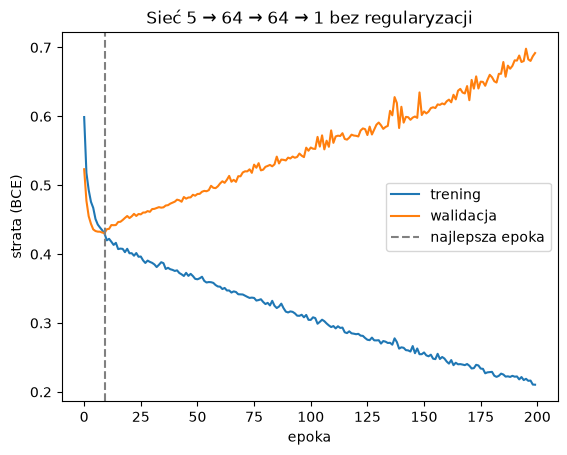

In [5]:
plt.plot(historia_tr, label="trening")
plt.plot(historia_val, label="walidacja")
plt.axvline(np.argmin(historia_val), color="gray", linestyle="--", label="najlepsza epoka")
plt.legend()
plt.title("Sieć 5 → 64 → 64 → 1 bez regularyzacji")
plt.xlabel("epoka")
plt.ylabel("strata (BCE)")

Ten sam obraz co tydzień temu: po kilku epokach krzywa walidacyjna zawraca.
Wszystko, co sieć „nauczyła się" po przerywanej linii, to zapamiętywanie szumu.

### Zatrzymaj, zanim będzie za późno

Najprostsze lekarstwo widać na wykresie: **przerwać trening, kiedy strata
walidacyjna przestaje spadać**, i wrócić do wag z najlepszej epoki. To jest
**wczesne zatrzymanie** (*early stopping*). W naszej funkcji robi je parametr
`cierpliwosc`:

- po każdej epoce sprawdzamy, czy strata walidacyjna jest najniższa
  z dotychczasowych — jeśli tak, zapamiętujemy kopię wag
  (`copy.deepcopy(model.state_dict())`),
- jeśli przez `cierpliwosc` epok z rzędu nie było poprawy — przerywamy,
- na koniec wczytujemy zapamiętane wagi (`model.load_state_dict(...)`).

Cierpliwość jest potrzebna, bo krzywa walidacyjna jest poszarpana — jedna gorsza
epoka nie znaczy jeszcze, że sieć zaczęła się przeuczać.

In [6]:
siec = duza_siec()
optymalizator = torch.optim.Adam(siec.parameters(), lr=0.001)
historia_tr, historia_val = trenuj(siec, dane, nn.BCELoss(), optymalizator, epoki=200, cierpliwosc=10)

print("trening trwał epok:", len(historia_val), "| najlepsza:", np.argmin(historia_val))
print("wczesne zatrzymanie   strata, F1:", ocen(siec, X_test_t, y_test))

trening trwał epok: 20 | najlepsza: 9
wczesne zatrzymanie   strata, F1: (0.431, 0.619)


Zamiast 200 epok — kilkanaście, a strata na teście spadła z prawie 0.6 do
ok. 0.43. Darmowa poprawa: krótszy trening i lepszy model.

> 📝 **`state_dict` — wagi sieci w słowniku**
>
> `model.state_dict()` zwraca wszystkie wagi i biasy sieci jako słownik
> `{nazwa_warstwy: tensor}`. `copy.deepcopy` robi z niego **niezależną
> kopię** — bez tego „zapamiętane" wagi zmieniałyby się razem z siecią. Tym
> samym słownikiem zapisuje się wytrenowaną sieć do pliku:
> `torch.save(model.state_dict(), "siec.pt")`.


## Weight decay i dropout

Wczesne zatrzymanie przerywa trening, zanim sieć zacznie się uczyć na pamięć.
Dwie kolejne metody sprawiają, że **w ogóle trudniej jej się uczyć na pamięć**.
Wszystkie trzy nazywa się wspólnie **regularyzacją**.

### Weight decay — kara za duże wagi

Sieć, która zapamiętuje pojedynczych klientów, potrzebuje do tego
**ogromnych wag** — żeby jeden mały szczegół zmieniał wynik o 180 stopni.
**Weight decay** (dosłownie „zanik wag") w każdym kroku lekko ściąga wszystkie
wagi w stronę zera. Waga zostaje duża tylko wtedy, gdy naprawdę pomaga na
wielu przykładach. To ta sama regularyzacja, którą `LogisticRegression`
stosowała domyślnie na zajęciach 4.

W PyTorch to jeden parametr optymalizatora:

In [7]:
siec = duza_siec()
optymalizator = torch.optim.Adam(siec.parameters(), lr=0.001, weight_decay=0.01)
historia_tr, historia_val = trenuj(siec, dane, nn.BCELoss(), optymalizator, epoki=200)

print("najniższa strata walidacyjna w epoce:", np.argmin(historia_val))
print("weight decay 0.01     strata, F1:", ocen(siec, X_test_t, y_test))

najniższa strata walidacyjna w epoce: 96
weight decay 0.01     strata, F1: (0.414, 0.632)


Tym razem nie przerywaliśmy treningu, a sieć i tak się nie przeuczyła —
najlepsza epoka wypadła daleko, a nie po kilku krokach.

### Dropout — losowe wyłączanie neuronów

**Dropout** działa inaczej: w każdym kroku treningu **losowo wyłącza** część
neuronów warstwy ukrytej — np. połowę. W kolejnym kroku wyłącza inną połowę.
Sieć nie może więc polegać na żadnym pojedynczym neuronie i musi rozłożyć
wiedzę na wiele z nich. Trochę jak drużyna, w której na każdy trening
przychodzi losowa połowa zawodników — wszyscy muszą umieć grać na kilku
pozycjach.

Dropout to osobna warstwa, którą wstawia się za aktywacją:

In [8]:
def duza_siec_dropout(p):
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(5, 64), nn.ReLU(), nn.Dropout(p),
        nn.Linear(64, 64), nn.ReLU(), nn.Dropout(p),
        nn.Linear(64, 1), nn.Sigmoid(),
    )

siec = duza_siec_dropout(0.5)
optymalizator = torch.optim.Adam(siec.parameters(), lr=0.001)
historia_tr, historia_val = trenuj(siec, dane, nn.BCELoss(), optymalizator, epoki=200)

print("dropout 0.5           strata, F1:", ocen(siec, X_test_t, y_test))

dropout 0.5           strata, F1: (0.4, 0.614)


`nn.Dropout(0.5)` wyłącza w każdym kroku losowe 50% wyjść poprzedniej warstwy.
Typowe wartości to 0.2–0.5.

> ⚠️ **`model.train()` i `model.eval()`**
>
> Dropout ma działać **tylko w czasie treningu**. Przy ocenie i przewidywaniu
> chcemy pełnej sieci, z wszystkimi neuronami. Przełącza to
> `model.train()` (dropout włączony) i `model.eval()` (wyłączony). Nasze
> funkcje `trenuj` i `ocen` robią to same — ale jeśli kiedyś będziesz liczyć
> przewidywania „ręcznie", zacznij od `model.eval()`. Zapomniane przełączenie
> to jeden z najczęstszych błędów: wyniki są wtedy losowo gorsze i za każdym
> razem inne.

### Porównanie

| Duża sieć 5 → 64 → 64 → 1 | Strata na teście |
|---|---|
| bez regularyzacji, 200 epok | ok. 0.59 |
| wczesne zatrzymanie | ok. 0.43 |
| weight decay 0.01 | ok. 0.41 |
| dropout 0.5 | ok. 0.40 |
| *dla porównania: mała sieć 5 → 8 → 1 z zajęć 5* | *ok. 0.42* |

Każda z trzech metod naprawiła przeuczenie, a duża sieć z regularyzacją
wyszła tak dobra jak mała — albo minimalnie lepsza. W praktyce stosuje się je
razem: trochę dropoutu, trochę weight decay i zawsze wczesne zatrzymanie jako
pas bezpieczeństwa.


## Funkcje straty

### Strata zależy od tego, co przewidujesz

Do tej pory zawsze przewidywaliśmy **klasę** (odejdzie / nie odejdzie) —
sigmoida na końcu i strata BCE. Ale sieć może też przewidywać **liczbę**: czas
dostawy, cenę mieszkania, sprzedaż w przyszłym tygodniu. To **regresja** —
znasz ją z zajęć 2 razem z metrykami MAE i RMSE. Zmieniają się wtedy dwie
rzeczy: ostatnia warstwa i funkcja straty.

| Zadanie | Przykład | Ostatnia warstwa | Strata | Metryka dla ludzi |
|---|---|---|---|---|
| klasyfikacja binarna | odejdzie czy nie | `Linear(…, 1)` + `Sigmoid()` | `nn.BCELoss()` | F1, precision, recall |
| regresja | ile minut potrwa dostawa | `Linear(…, 1)` **bez aktywacji** | `nn.MSELoss()` albo `nn.L1Loss()` | MAE, RMSE |
| klasyfikacja wieloklasowa | która z 10 cyfr | `Linear(…, 10)` | `nn.CrossEntropyLoss()` | accuracy |

W regresji na końcu nie ma sigmoidy — ona ścisnęłaby wynik do przedziału 0–1,
a dostawa trwa 35 minut, nie 0.35. Ostatni neuron zwraca po prostu ważoną
sumę, czyli dowolną liczbę.

- **`MSELoss`** — średni **kwadrat** błędu. Pomyłka o 10 minut kosztuje 100,
  o 20 minut — 400. Mocno karze duże pomyłki.
- **`L1Loss`** — średni błąd **bez kwadratu**, czyli dokładnie MAE. Spokojniej
  traktuje pojedyncze wartości odstające.

Klasyfikacją wieloklasową zajmiemy się na zajęciach 7, przy obrazkach.

> 📝 **A `BCEWithLogitsLoss`?**
>
> W cudzym kodzie zobaczysz zwykle `nn.BCEWithLogitsLoss()` i sieć **bez**
> sigmoidy na końcu. To to samo co sigmoida + `BCELoss`, tylko połączone
> w jedną funkcję, która liczy się dokładniej przy bardzo pewnych
> przewidywaniach (p = 0.99999). Przy takim kodzie prawdopodobieństwo
> dostajesz przez `torch.sigmoid(model(X))`. My zostajemy przy sigmoidzie
> w modelu, bo tak łatwiej czytać kod.


## Sieć do regresji — czas dostawy

### Dane MeritoEats

`dostawy_czyste.csv` to oba miesiące z DS w Pythonie, wyczyszczone
i połączone z restauracjami. Cechy budujemy jak na zajęciach 5 z DS
— godzina, weekend, pogoda jako flagi, kuchnia jako one-hot:

In [9]:
URL_DOSTAWY = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/dostawy_czyste.csv"
dost = pd.read_csv(URL_DOSTAWY, parse_dates=["data_godzina"])

dost["godzina"] = dost["data_godzina"].dt.hour
dost["weekend"] = (dost["data_godzina"].dt.day_of_week >= 5).astype(int)
dost["deszcz"] = (dost["pogoda"] == "deszcz").astype(int)
dost["snieg"] = (dost["pogoda"] == "śnieg").astype(int)
dost = pd.concat([dost, pd.get_dummies(dost["kuchnia"], prefix="kuchnia", dtype=int)], axis=1)

cechy_d = (["odleglosc_km", "liczba_pozycji", "wartosc_zl", "godzina", "weekend", "deszcz", "snieg"]
           + [k for k in dost.columns if k.startswith("kuchnia_")])
print(len(dost), "zamówień,", len(cechy_d), "cech")

3453 zamówień, 13 cech


Kolumny `ocena` nie bierzemy — klient wystawia ją **po** dostawie, więc to
wyciek. Nie bierzemy też `obiecany_czas_min`: to wynik wzoru aplikacji,
z którym chcemy się porównać.

### Skalujemy także cel

Podział robimy jak zawsze, tylko bez `stratify` — to ma sens przy klasach, a nie
przy minutach. Nowość: oprócz cech skalujemy też **zmienną celu**.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    dost[cechy_d], dost["czas_dostawy_min"], test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

scaler_d = StandardScaler().fit(X_tr)
srednia, odchylenie = y_tr.mean(), y_tr.std()
print("średni czas dostawy:", round(srednia, 1), "min, odchylenie:", round(odchylenie, 1), "min")

def X_na_tensor(X):
    return torch.tensor(scaler_d.transform(X), dtype=torch.float32)

def y_na_tensor(y):
    return torch.tensor(((y - srednia) / odchylenie).values, dtype=torch.float32).view(-1, 1)

dane_d = (X_na_tensor(X_tr), y_na_tensor(y_tr), X_na_tensor(X_val), y_na_tensor(y_val))
X_test_d = X_na_tensor(X_test)

średni czas dostawy: 36.9 min, odchylenie: 11.5 min


Dlaczego? Świeża sieć zwraca liczby bliskie zera, a prawidłowa odpowiedź to
ok. 37 minut. Zanim sieć zacznie się uczyć czegokolwiek ciekawego, musiałaby
długo „dojeżdżać" do trzydziestu kilku — Adam robi małe kroki, więc zajęłoby
to dziesiątki epok, a wynik zależałby od przypadku. Po skalowaniu cel ma
średnią 0 i odchylenie 1, czyli sieć startuje blisko dobrej odpowiedzi.
Przewidywania zamieniamy z powrotem na minuty: `p * odchylenie + srednia`.

### Model liniowy i sieć

Trenujemy dwa modele: jeden neuron bez aktywacji (czyli zwykła regresja
liniowa) i sieć z warstwą ukrytą. Funkcja `trenuj` jest ta sama — zmienia się
tylko strata:

In [11]:
def przewidz_minuty(model, X_t):
    model.eval()
    with torch.no_grad():
        return model(X_t).numpy().ravel() * odchylenie + srednia

torch.manual_seed(42)
liniowy = nn.Linear(len(cechy_d), 1)
trenuj(liniowy, dane_d, nn.MSELoss(), torch.optim.Adam(liniowy.parameters(), lr=0.001), cierpliwosc=10)

torch.manual_seed(42)
siec_d = nn.Sequential(nn.Linear(len(cechy_d), 32), nn.ReLU(), nn.Linear(32, 1))
trenuj(siec_d, dane_d, nn.MSELoss(), torch.optim.Adam(siec_d.parameters(), lr=0.001), cierpliwosc=10)

p_liniowy = przewidz_minuty(liniowy, X_test_d)
p_siec = przewidz_minuty(siec_d, X_test_d)

print("średnia dla wszystkich MAE:", round(mean_absolute_error(y_test, np.full(len(y_test), srednia)), 2), "min")
print("model liniowy          MAE:", round(mean_absolute_error(y_test, p_liniowy), 2), "min")
print("sieć 13 → 32 → 1       MAE:", round(mean_absolute_error(y_test, p_siec), 2), "min")

średnia dla wszystkich MAE: 9.05 min
model liniowy          MAE: 5.15 min
sieć 13 → 32 → 1       MAE: 4.63 min


MAE czyta się wprost: **o ile minut średnio myli się model**. Przewidywanie
„każda dostawa potrwa średnio 37 minut" myli się o 9 minut. Model liniowy —
o ok. 5. Sieć jest lepsza o mniej więcej pół minuty. Skąd ta różnica?

### Gdzie myli się model liniowy

Policzmy średni błąd (prawdziwy czas minus przewidziany) osobno dla każdej
godziny:

Text(0, 0.5, 'prawdziwy − przewidziany czas (min)')

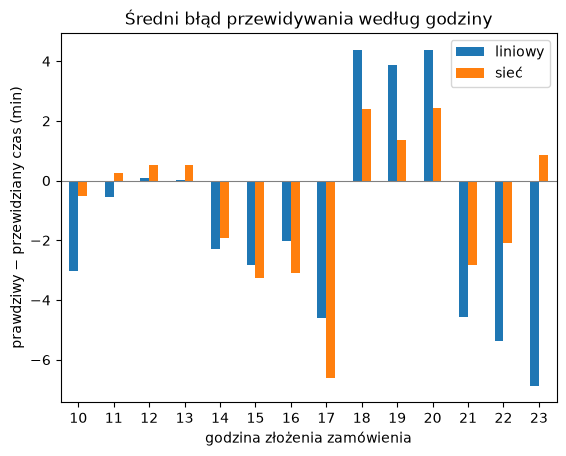

In [12]:
bledy = pd.DataFrame({
    "godzina": X_test["godzina"].values,
    "liniowy": y_test.values - p_liniowy,
    "sieć": y_test.values - p_siec,
})
bledy.groupby("godzina")[["liniowy", "sieć"]].mean().plot(
    kind="bar", title="Średni błąd przewidywania według godziny")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xticks(rotation=0)
plt.xlabel("godzina złożenia zamówienia")
plt.ylabel("prawdziwy − przewidziany czas (min)")

Model liniowy ma dla godziny jedną wagę, więc umie powiedzieć tylko „im
później, tym dłużej" (albo krócej). Wieczorny szczyt 18–20 jest dla niego
niewidoczny — w szczycie **zaniża** czas o ok. 4 minuty, a po 21:00
**zawyża** go o 5–7 minut. Sieć zauważyła, że szczyt to szczyt: w godzinach
18–20 jej błąd jest mniej więcej o połowę mniejszy, a późnym wieczorem prawie
znika. Idealna nie jest — o 17:00 myli się nawet bardziej niż model liniowy,
bo zamówień z tej godziny jest mało. Ten sam mechanizm co z wizytami na
siłowni tydzień temu, tylko teraz w minutach.


## Ściągawka

| Chcę… | Kod |
|---|---|
| Adam (dobry start) | `torch.optim.Adam(model.parameters(), lr=0.001)` |
| SGD z momentum | `torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)` |
| weight decay | `torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)` |
| dropout | `nn.Dropout(0.3)` za `nn.ReLU()` |
| tryb treningu / oceny | `model.train()` / `model.eval()` |
| kopia wag | `copy.deepcopy(model.state_dict())` |
| wczytać zapamiętane wagi | `model.load_state_dict(wagi)` |
| trening z wczesnym zatrzymaniem | `trenuj(model, dane, strata, optymalizator, epoki=200, cierpliwosc=10)` |
| klasyfikacja binarna | `Linear(…, 1)` + `Sigmoid()`, `nn.BCELoss()` |
| regresja | `Linear(…, 1)` bez aktywacji, `nn.MSELoss()` albo `nn.L1Loss()` |
| skalowanie celu w regresji | `(y - srednia) / odchylenie`, z powrotem: `p * odchylenie + srednia` |
| błąd w jednostkach celu | `mean_absolute_error(y_test, p)` |
| podział bez stratify (regresja) | `train_test_split(X, y, test_size=0.2, random_state=42)` |

## Zadanie 6

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_6/#zadanie-6-regularyzacja-i-czas-dostawy-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.